# HIT140 Objective 2 — FIFA World Cup 2026: predicting goal difference and goals scored

**Group project, Assessment 3.** Two linear regression tasks, each with exactly 8 explanatory variables:

- **Linear Regression 2.1:** predict the **goal difference** of a match (104 rows, one per match).
- **Linear Regression 2.2:** predict the **goals scored by one team** in a match (208 rows, one per team per match).

After the two linear models, we test other models (Ridge, Lasso, Random Forest, Gradient Boosting, Poisson) on the same data to see whether anything beats plain linear regression.

**How this notebook is organised**

1. Load the data and check it is correct
2. Understand the data (EDA)
3. Build the explanatory variables (using only information known before kick-off)
4. Choose the 8 variables for each model using EDA on the training matches only
5. Linear Regression 2.1
6. Linear Regression 2.2
7. Improving the models (feature engineering, regularisation, tuning)
8. Competing models and recommendation
9. Summary tables for the report

**Data source:** the FBref Scores & Fixtures table for the World Cup (one of the three sources in the brief). Every variable is built from this table. We did **not** use any FIFA ranking: the only ranking we could find was published *after* the tournament, so using it would leak results into the model.

## 1. Setup and loading the data

In [1]:
# Libraries
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
Path("figures").mkdir(exist_ok=True)

# One simple colour scheme used in every chart (colour-blind friendly)
BLUE, ORANGE, GREY, GREEN = "#2E6FA7", "#E08A1E", "#8A8F98", "#3B9B6B"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Use data/fbref_matches.csv if it exists next to the notebook
raw = pd.read_csv("data/fbref_matches.csv", parse_dates=["Date"])
print("Rows:", len(raw), "| Columns:", raw.shape[1])
raw.head(3)

Rows: 104 | Columns: 13


,Round,Wk,Day,Date,Time,Home,Score,Away,Attendance,Venue,Referee,Match Report,Notes
0,Group stage,1.0,Thu,2026-06-11,13:00 (05:00),Mexico mx,2-0,za South Africa,80824,Estadio Banorte (Neutral Site),Wilton Sampaio,Match Report,NaN
1,Group stage,1.0,Thu,2026-06-11,20:00 (12:00),Korea Republic kr,2-1,cz Czechia,44985,Estadio Akron (Neutral Site),Amin Omar,Match Report,NaN
2,Group stage,1.0,Fri,2026-06-12,15:00 (05:00),Canada ca,1-1,ba Bosnia-Herz,43002,BMO Field (Neutral Site),Facundo Tello,Match Report,NaN


## 2. Data cleaning and integrity checks

Things we need to fix before any modelling:

- **Penalty shoot-out scores** look like `(3) 1-1 (4)`. The number in brackets is the shoot-out, not goals scored. We take the score *between* the brackets (the score after extra time) as the match score, and keep the shoot-out as a separate note. In an earlier version only 100 of 104 scores were read, because these four rows were skipped.
- **Team names** have a country code stuck on (`Mexico mx`, `za South Africa`). We remove it.
- **Match order:** we sort by date and kick-off time and give each match an ID. The ID is only a label and is never used as a predictor.

In [2]:
df = raw.copy()
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]

# 1) Score: remove any shoot-out numbers in brackets, then read "home-away"
df["went_to_penalties"] = df["score"].str.contains(r"\(\d+\)")
clean_score = df["score"].str.replace(r"\(\d+\)", "", regex=True)
df[["home_goals", "away_goals"]] = clean_score.str.extract(r"(\d+)\s*-\s*(\d+)").astype(int)
df["extra_time"] = df["notes"].fillna("").str.contains("Extra Time|extra time")

# 2) Team names: home has the code at the END, away has it at the START
df["home_team"] = df["home"].str.replace(r"\s+[a-z]{2,3}$", "", regex=True).str.strip()
df["away_team"] = df["away"].str.replace(r"^[a-z]{2,3}\s+", "", regex=True).str.strip()

# 3) Order matches in time and give each one an ID
df["kickoff_local"] = df["time"].str.extract(r"^(\d{1,2}:\d{2})")[0]
df = df.sort_values(["date", "kickoff_local"]).reset_index(drop=True)
df["match_id"] = np.arange(1, len(df) + 1)

# 4) The two targets
df["goal_difference"] = df["home_goals"] - df["away_goals"]
df["total_goals"] = df["home_goals"] + df["away_goals"]
df["stage"] = np.where(df["round"].eq("Group stage"), "Group", "Knockout")

df[["match_id","date","round","home_team","home_goals","away_goals","away_team","went_to_penalties"]].head()

,match_id,date,round,home_team,home_goals,away_goals,away_team,went_to_penalties
0,1,2026-06-11,Group stage,Mexico,2,0,South Africa,False
1,2,2026-06-11,Group stage,Korea Republic,2,1,Czechia,False
2,3,2026-06-12,Group stage,Canada,1,1,Bosnia-Herz,False
3,4,2026-06-12,Group stage,USA,4,1,Paraguay,False
4,5,2026-06-13,Group stage,Qatar,1,1,Switzerland,False


In [3]:
# Integrity checks. If any assertion fails the notebook stops, so we cannot model bad data by accident.
teams = pd.concat([df.home_team, df.away_team])
checks = {
    "104 matches": len(df) == 104,
    "no missing goals": df[["home_goals","away_goals"]].notna().all().all(),
    "no duplicate fixtures": not df.duplicated(["date","home_team","away_team"]).any(),
    "48 distinct teams": teams.nunique() == 48,
    "72 group + 32 knockout": (df.stage.value_counts().to_dict() == {"Group":72, "Knockout":32}),
    "each team played 3 group games": (pd.concat([df[df.stage=="Group"].home_team, df[df.stage=="Group"].away_team]).value_counts() == 3).all(),
    "penalty rows found (4 expected)": df.went_to_penalties.sum() == 4,
    "dates in order": df.date.is_monotonic_increasing,
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
assert all(checks.values())
print("\nMissing values in the columns we use:", int(df[["date","home_team","away_team","home_goals","away_goals","round"]].isna().sum().sum()))
print("Team names, quick look:", sorted(teams.unique())[:8], "...")

PASS 104 matches
PASS no missing goals
PASS no duplicate fixtures
PASS 48 distinct teams
PASS 72 group + 32 knockout
PASS each team played 3 group games
PASS penalty rows found (4 expected)
PASS dates in order

Missing values in the columns we use: 0
Team names, quick look: ['Algeria', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Bosnia-Herz', 'Brazil', 'Cabo Verde'] ...


**What this cell showed:** all 8 checks pass. We have 104 matches (72 group, 32 knockout), 48 teams, no duplicates and no missing scores. The 4 penalty shoot-out matches are now read correctly, so the data has 104 usable rows instead of 100.

**One thing to remember:** the match score includes extra time. The shoot-out itself is not counted as goals.

## 3. Exploratory data analysis (EDA) — understanding the data

First we look at the matches themselves: how many goals, how big the margins are, and how the tournament changed as it went on. This is done on all 104 matches because it only describes the tournament. It does **not** choose variables. Variable selection happens later, on training matches only.

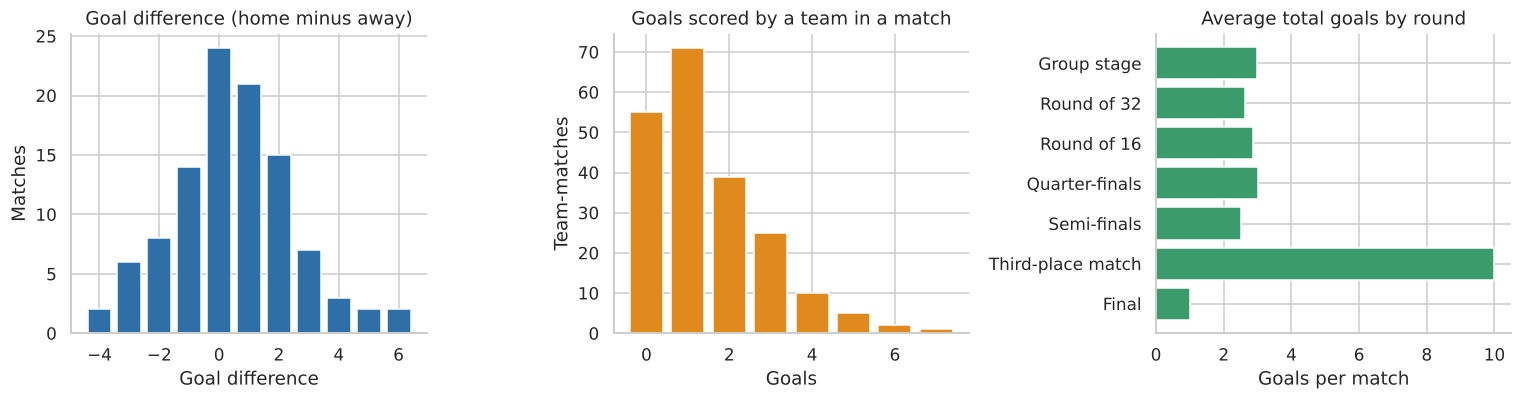

Mean goals per team-match: 1.48 | variance: 1.94
Goal difference: mean 0.48 | std 2.02
Listed-home win / draw / listed-away win: 0.48 0.23 0.29
Matches with 4+ goal margin: 9


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

# (a) Goal difference distribution
gd_counts = df.goal_difference.value_counts().sort_index()
axes[0].bar(gd_counts.index, gd_counts.values, color=BLUE)
axes[0].set(title="Goal difference (home minus away)", xlabel="Goal difference", ylabel="Matches")

# (b) Goals scored by one team (the target of model 2.2)
team_goals = pd.concat([df.home_goals, df.away_goals])
tg_counts = team_goals.value_counts().sort_index()
axes[1].bar(tg_counts.index, tg_counts.values, color=ORANGE)
axes[1].set(title="Goals scored by a team in a match", xlabel="Goals", ylabel="Team-matches")

# (c) Average total goals by round
order = ["Group stage","Round of 32","Round of 16","Quarter-finals","Semi-finals","Third-place match","Final"]
by_round = df.groupby("round").total_goals.mean().reindex(order)
axes[2].barh(range(len(order)), by_round.values, color=GREEN)
axes[2].set_yticks(range(len(order))); axes[2].set_yticklabels(order); axes[2].invert_yaxis()
axes[2].set(title="Average total goals by round", xlabel="Goals per match")
plt.tight_layout(); plt.savefig("figures/fig1_target_distributions.png", dpi=200); plt.show()

print("Mean goals per team-match:", round(team_goals.mean(), 2), "| variance:", round(team_goals.var(), 2))
print("Goal difference: mean", round(df.goal_difference.mean(), 2), "| std", round(df.goal_difference.std(), 2))
print("Listed-home win / draw / listed-away win:", (df.goal_difference>0).mean().round(2), (df.goal_difference==0).mean().round(2), (df.goal_difference<0).mean().round(2))
print("Matches with 4+ goal margin:", int((df.goal_difference.abs()>=4).sum()))

**What the charts show**

- **Goal difference** is centred just above zero (mean 0.48, std 2.0). Nine matches ended with a margin of 4 or more, so there are a few big outliers, for example Germany 7-1 Curaçao and the 4-6 third-place match.
- **Goals per team** average 1.48, with a variance of 1.94. Most teams score 0, 1 or 2 goals. Because goals are small whole numbers, a straight-line model can in theory predict impossible negative goals (we check this later).
- **Group and knockout matches** have similar scoring (about 3 goals per match), apart from the 10-goal third-place match.
- The team **listed first** on FBref won 48% of matches, drew 23% and lost 29%. This is *not* real home advantage, because every match is on neutral ground, but listed-first teams do score more (1.72 vs 1.24 goals). This is a useful clue for model 2.2.

## 4. Building the explanatory variables (only information known before kick-off)

**The rule:** a variable for match *M* may only use matches played **before** match *M*. This stops the model from "seeing" the answer.

**Two problems and how we handle them**

1. **A team's first match has no history.** Setting history to zero would pretend the team is terrible. Instead we use a *shrunk average*: `(goals so far + 2 × tournament average so far) / (matches played + 2)`. With no matches played the value equals the tournament average, so it is neutral. As a team plays more, its own record counts for more. The tournament average at a given date only uses earlier matches. For the very first match we use a typical World Cup scoring rate of 1.3 goals per team.
2. **No outside data.** FIFA rankings found online are from after the tournament. So the variables below come from the FBref table plus fixed facts that do not depend on results: host country, confederation, kick-off order and rest days.

**Candidate variables**

| Family | Meaning | Used in |
|---|---|---|
| gf | shrunk goals scored per match so far | 2.1 and 2.2 (**shared**) |
| ga | shrunk goals conceded per match so far | 2.1 and 2.2 (**shared**) |
| host | team is a host nation (Mexico, USA, Canada) | 2.1 and 2.2 (**shared**) |
| ppg | shrunk points per match so far | 2.1 only |
| draw rate | shrunk share of draws | 2.1 only |
| rest days | days since the team's last match (max 7) | 2.1 only |
| previous match extra time | the team's last match went to extra time or penalties | 2.1 only |
| strong confederation | team is from UEFA or CONMEBOL | 2.1 only |
| knockout | match is a knockout match | 2.1 only |
| failed-to-score rate | shrunk share of matches without scoring | 2.2 only |
| clean-sheet rate | shrunk share of matches without conceding | 2.2 only |
| win rate | shrunk share of wins | 2.2 only |
| listed as home | team is the one FBref lists first | 2.2 only |
| tournament day | days since opening match | 2.2 only |

Only **three** explanatory-variable families are shared between the two models, which is within the limit of four set by the lecturer. In model 2.1 each variable is a *difference* (home minus away). In model 2.2 each variable describes the team being predicted or its opponent.

In [5]:
# Fixed facts that do not depend on match results
CONFED = {
 "CONCACAF": ["Mexico","USA","Canada","Haiti","Curaçao","Panama"],
 "CAF": ["South Africa","Egypt","Morocco","Tunisia","Senegal","Ghana","Côte d'Ivoire","Algeria","Cabo Verde","Congo DR"],
 "AFC": ["Korea Republic","Qatar","Australia","Japan","Saudi Arabia","IR Iran","Iraq","Jordan","Uzbekistan"],
 "OFC": ["New Zealand"],
 "CONMEBOL": ["Brazil","Ecuador","Uruguay","Argentina","Paraguay","Colombia"],
 "UEFA": ["Czechia","Bosnia-Herz","Switzerland","Türkiye","Scotland","Germany","Netherlands","Sweden","Belgium",
          "Spain","France","Norway","Austria","Portugal","England","Croatia"],
}
team_confed = {t: c for c, ts in CONFED.items() for t in ts}
HOSTS = {"Mexico", "USA", "Canada"}
assert set(team_confed) == set(pd.concat([df.home_team, df.away_team]).unique()), "confederation map must cover all 48 teams"

# Long table: one row per team per match
def side(d, team, opp, gf, ga, listed_home):
    out = d[["match_id","date","stage"]].copy()
    out["team"], out["opp"] = d[team], d[opp]
    out["gf"], out["ga"] = d[gf], d[ga]
    out["listed_home"] = listed_home
    return out
tg = pd.concat([side(df,"home_team","away_team","home_goals","away_goals",1),
                side(df,"away_team","home_team","away_goals","home_goals",0)])
tg["went_et"] = tg.match_id.map(df.set_index("match_id").extra_time.astype(int) | df.set_index("match_id").went_to_penalties.astype(int))
tg = tg.sort_values(["date","match_id","listed_home"], ascending=[True,True,False]).reset_index(drop=True)

# Outcome columns for each team-match (these describe the match itself, so they are only used AFTER shifting)
tg["pts"]  = np.select([tg.gf>tg.ga, tg.gf==tg.ga], [3,1], 0)
tg["win"]  = (tg.gf>tg.ga).astype(int)
tg["draw"] = (tg.gf==tg.ga).astype(int)
tg["cs"]   = (tg.ga==0).astype(int)
tg["fts"]  = (tg.gf==0).astype(int)

K = 2  # strength of the pull towards the tournament average (2 pseudo-matches)
FALLBACK = {"gf":1.3, "ga":1.3, "pts":1.3, "win":0.375, "draw":0.25, "cs":0.25, "fts":0.25}  # only used for the opening match

def league_prior_by_date(stat):
    # Tournament average of `stat` using ONLY matches on earlier dates
    prior = {}
    for d in sorted(tg.date.unique()):
        past = tg[tg.date < d]
        prior[d] = past[stat].mean() if len(past) else FALLBACK[stat]
    return tg.date.map(prior)

for s in ["gf","ga","pts","win","draw","cs","fts"]:
    g = tg.groupby("team")[s]
    prev_sum = g.cumsum() - tg[s]                   # sum over this team's EARLIER matches only
    n_prev = tg.groupby("team").cumcount()          # number of earlier matches
    tg[f"{s}_form"] = (prev_sum + K * league_prior_by_date(s)) / (n_prev + K)
tg["matches_played"] = tg.groupby("team").cumcount()
# Did the team's PREVIOUS match go to extra time? (a known fatigue factor before kick-off; 0 for a first match)
tg["prev_et"] = tg.groupby("team").went_et.shift(1).fillna(0)

# Rest days: days since the team's previous match, capped at 7 (first match = 7, i.e. fully rested)
tg["rest_days"] = (tg.date - tg.groupby("team").date.shift(1)).dt.days.fillna(7).clip(upper=7)
tg["is_host"] = tg.team.isin(HOSTS).astype(int)
tg["strong_confed"] = tg.team.map(team_confed).isin(["UEFA","CONMEBOL"]).astype(int)
tg["knockout"] = (tg.stage == "Knockout").astype(int)
tg["tournament_day"] = (tg.date - tg.date.min()).dt.days
feat_cols = ["prev_et","gf_form","ga_form","pts_form","win_form","draw_form","cs_form","fts_form","matches_played","rest_days",
             "is_host","strong_confed","knockout","tournament_day","listed_home"]
lookup = tg.set_index(["match_id","team"])[feat_cols]
print("Team-match rows:", len(tg))
tg[["match_id","team","opp","gf","ga","gf_form","ga_form","pts_form","rest_days","matches_played"]].head(6)

Team-match rows: 208


,match_id,team,opp,gf,ga,gf_form,ga_form,pts_form,rest_days,matches_played
0,1,Mexico,South Africa,2,0,1.30,1.30,1.3,7.0,0
1,1,South Africa,Mexico,0,2,1.30,1.30,1.3,7.0,0
2,2,Korea Republic,Czechia,2,1,1.30,1.30,1.3,7.0,0
3,2,Czechia,Korea Republic,1,2,1.30,1.30,1.3,7.0,0
4,3,Canada,Bosnia-Herz,1,1,1.25,1.25,1.5,7.0,0
5,3,Bosnia-Herz,Canada,1,1,1.25,1.25,1.5,7.0,0


In [6]:
# ---- Dataset for Linear Regression 2.1: one row per match, features = home minus away ----
H = lookup.loc[list(zip(df.match_id, df.home_team))].reset_index(drop=True)
A = lookup.loc[list(zip(df.match_id, df.away_team))].reset_index(drop=True)
m21 = df[["match_id","date","round","home_team","away_team","home_goals","away_goals","goal_difference"]].copy()
m21["gf_diff"]            = H.gf_form - A.gf_form
m21["ga_diff"]            = H.ga_form - A.ga_form
m21["host_diff"]          = H.is_host - A.is_host
m21["ppg_diff"]           = H.pts_form - A.pts_form
m21["draw_rate_diff"]     = H.draw_form - A.draw_form
m21["rest_days_diff"]     = H.rest_days - A.rest_days
m21["prev_et_diff"]       = H.prev_et - A.prev_et
m21["strong_confed_diff"] = H.strong_confed - A.strong_confed
m21["knockout"]           = H.knockout          # same for both teams, so it is not a difference
POOL_21 = ["gf_diff","ga_diff","host_diff","ppg_diff","draw_rate_diff","rest_days_diff","prev_et_diff","strong_confed_diff","knockout"]

# ---- Dataset for Linear Regression 2.2: one row per team per match ----
T = lookup.loc[list(zip(tg.match_id, tg.team))].reset_index(drop=True)
O = lookup.loc[list(zip(tg.match_id, tg.opp))].reset_index(drop=True)
m22 = tg[["match_id","date","team","opp","gf"]].rename(columns={"gf":"goals_scored"}).reset_index(drop=True)
m22["team_gf"]       = T.gf_form
m22["team_ga"]       = T.ga_form
m22["is_host"]       = T.is_host
m22["team_fts_rate"] = T.fts_form
m22["opp_gf"]        = O.gf_form
m22["opp_ga"]        = O.ga_form
m22["opp_cs_rate"]   = O.cs_form
m22["opp_win_rate"]  = O.win_form
m22["listed_home"]   = T.listed_home
m22["tournament_day"]= T.tournament_day
POOL_22 = ["team_gf","team_ga","is_host","team_fts_rate","opp_gf","opp_ga","opp_cs_rate","opp_win_rate","listed_home","tournament_day"]

print("Model 2.1 data:", m21.shape, "| Model 2.2 data:", m22.shape)
assert len(m21) == 104 and len(m22) == 208
assert m21[POOL_21].notna().all().all() and m22[POOL_22].notna().all().all()
m21.to_csv("data/model21_dataset.csv", index=False); m22.to_csv("data/model22_dataset.csv", index=False)

Model 2.1 data: (104, 17) | Model 2.2 data: (208, 15)


In [7]:
# LEAK CHECK: rebuild one feature the slow, obvious way for several random matches
# and confirm it equals what we stored. If a match could see its own result, these would differ.
rng = np.random.default_rng(SEED)
for mid in rng.choice(df.match_id.values, 6, replace=False):
    row = df[df.match_id == mid].iloc[0]
    past = tg[tg.date < row.date]                      # strictly earlier days
    team_past = tg[(tg.team == row.home_team) & (tg.date < row.date)]
    prior = past.gf.mean() if len(past) else FALLBACK["gf"]
    slow = (team_past.gf.sum() + K * prior) / (len(team_past) + K)
    stored = lookup.loc[(mid, row.home_team), "gf_form"]
    assert abs(slow - stored) < 1e-9, (mid, slow, stored)
print("Leak check passed: stored features equal features computed from earlier matches only.")
opening = m21.iloc[0]
print("Opening match (no history): gf_diff =", round(opening.gf_diff, 3), "(neutral, as intended)")

Leak check passed: stored features equal features computed from earlier matches only.
Opening match (no history): gf_diff = 0.0 (neutral, as intended)


**What this cell showed:** both datasets have the right size (104 rows for 2.1, 208 rows for 2.2). The leak check passed. Features rebuilt the slow way from earlier matches only match the stored ones, and the opening match gets a neutral value (difference 0), not a made-up one.

**Why shrinkage is better than filling with zero or the average of all matches:** a team with one 5-0 win is not really a 5-goals-per-game team. The shrunk average pulls such small samples back towards the tournament average, and this is learned from earlier matches only.

## 5. Train / test split

Matches are in time order, so we train on the **first 80% of matches** (83 matches) and test on the **last 21 matches**. A random split would let the model learn from matches played *after* the ones it is tested on. In model 2.2 both team-rows of a match always stay on the same side of the split.

In [8]:
N_TRAIN = int(0.8 * 104)                       # 83 matches
train_ids = set(range(1, N_TRAIN + 1))
tr21, te21 = m21[m21.match_id.isin(train_ids)].copy(), m21[~m21.match_id.isin(train_ids)].copy()
tr22, te22 = m22[m22.match_id.isin(train_ids)].copy(), m22[~m22.match_id.isin(train_ids)].copy()
print("Model 2.1 -> train", len(tr21), "rows / test", len(te21), "rows  | test dates:", te21.date.min().date(), "to", te21.date.max().date())
print("Model 2.2 -> train", len(tr22), "rows / test", len(te22), "rows")
print("Stage mix in test set:", te21["round"].value_counts().to_dict())

Model 2.1 -> train 83 rows / test 21 rows  | test dates: 2026-07-02 to 2026-07-19
Model 2.2 -> train 166 rows / test 42 rows
Stage mix in test set: {'Round of 16': 8, 'Round of 32': 5, 'Quarter-finals': 4, 'Semi-finals': 2, 'Third-place match': 1, 'Final': 1}


## 6. EDA to choose the 8 variables (training matches only)

Following the unit guidance, we first nominated candidates using football common sense (table above). Now EDA checks which ones really relate to the target. This uses **training matches only**, so the test matches never influence which variables we pick.

For each candidate we look at the correlation with the target and at multicollinearity (VIF: how much a variable is just a mix of the others; above 10 is a problem). Then:

1. drop any variable with VIF above 10, one at a time, and
2. if more than 8 remain, drop the one with the weakest correlation to the target.

In [9]:
def vif_table(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X.columns)

def select_features(train, pool, target, n_keep=8):
    # Training-only selection: remove VIF > 10 first, then weakest |correlation| until n_keep remain
    keep, log = list(pool), []
    for f in list(keep):                      # a column that never changes carries no information
        if train[f].std() == 0: log.append((f, "constant in training data")); keep.remove(f)
    while True:
        vifs = vif_table(train[keep])
        if vifs.max() > 10:
            drop = vifs.idxmax(); log.append((drop, f"VIF {vifs.max():.1f} > 10")); keep.remove(drop); continue
        if len(keep) > n_keep:
            r = train[keep].corrwith(train[target]).abs()
            drop = r.idxmin(); log.append((drop, f"weakest |r| = {r.min():.3f}")); keep.remove(drop); continue
        break
    return keep, log

sel_tables = {}
for name, train, pool, target in [("2.1", tr21, POOL_21, "goal_difference"), ("2.2", tr22, POOL_22, "goals_scored")]:
    r = train[pool].corrwith(train[target])
    v = vif_table(train[pool])
    sel_tables[name] = pd.DataFrame({"correlation_with_target": r.round(3), "VIF": v.round(2)}).sort_values("correlation_with_target", key=abs, ascending=False)
    print(f"\nModel {name}: candidate variables (training matches only)")
    display(sel_tables[name])

FEATURES_21, log21 = select_features(tr21, POOL_21, "goal_difference")
FEATURES_22, log22 = select_features(tr22, POOL_22, "goals_scored")
print("\nModel 2.1 dropped:", log21); print("Model 2.1 final 8:", FEATURES_21)
print("\nModel 2.2 dropped:", log22); print("Model 2.2 final 8:", FEATURES_22)
assert len(FEATURES_21) == 8 and len(FEATURES_22) == 8
shared = {"gf","ga","host"}
fam = lambda f: ("gf" if f in ("gf_diff","team_gf","opp_gf") else "ga" if f in ("ga_diff","team_ga","opp_ga") else "host" if "host" in f else f)
fam21, fam22 = {fam(f) for f in FEATURES_21}, {fam(f) for f in FEATURES_22}
print("\nShared variable families between 2.1 and 2.2:", fam21 & fam22, "-> count =", len(fam21 & fam22), "(limit is 4)")
assert len(fam21 & fam22) <= 4


Model 2.1: candidate variables (training matches only)


,correlation_with_target,VIF
ga_diff,-0.362,2.11
ppg_diff,0.322,3.40
strong_confed_diff,0.277,1.27
host_diff,0.267,1.38
draw_rate_diff,0.248,1.20
gf_diff,0.167,2.22
rest_days_diff,0.085,1.06
knockout,0.065,1.19
prev_et_diff,NaN,NaN



Model 2.2: candidate variables (training matches only)


,correlation_with_target,VIF
listed_home,0.231,1.03
opp_cs_rate,-0.227,2.36
opp_ga,0.206,1.82
opp_win_rate,-0.189,3.03
team_ga,-0.188,1.10
is_host,0.155,1.17
opp_gf,-0.118,2.41
team_fts_rate,-0.055,1.84
team_gf,0.048,1.91
tournament_day,-0.024,1.54



Model 2.1 dropped: [('prev_et_diff', 'constant in training data')]
Model 2.1 final 8: ['gf_diff', 'ga_diff', 'host_diff', 'ppg_diff', 'draw_rate_diff', 'rest_days_diff', 'strong_confed_diff', 'knockout']

Model 2.2 dropped: [('tournament_day', 'weakest |r| = 0.024'), ('team_gf', 'weakest |r| = 0.048')]
Model 2.2 final 8: ['team_ga', 'is_host', 'team_fts_rate', 'opp_gf', 'opp_ga', 'opp_cs_rate', 'opp_win_rate', 'listed_home']

Shared variable families between 2.1 and 2.2: {'host', 'ga', 'gf'} -> count = 3 (limit is 4)


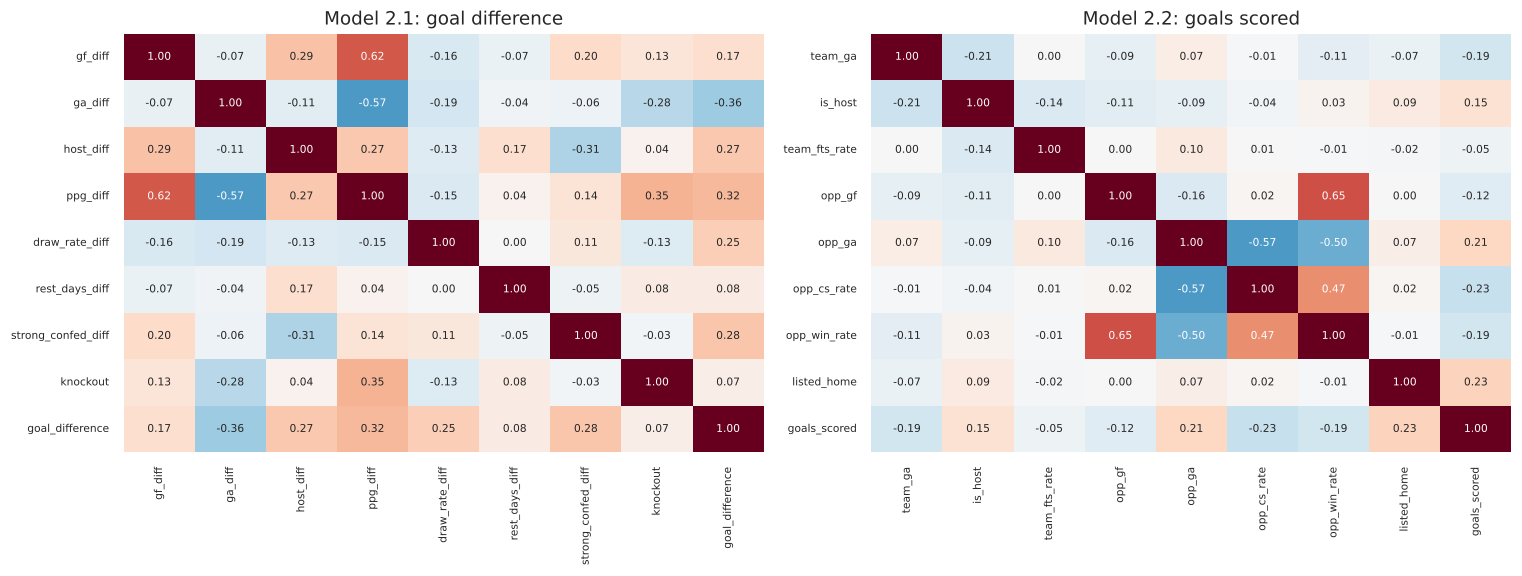

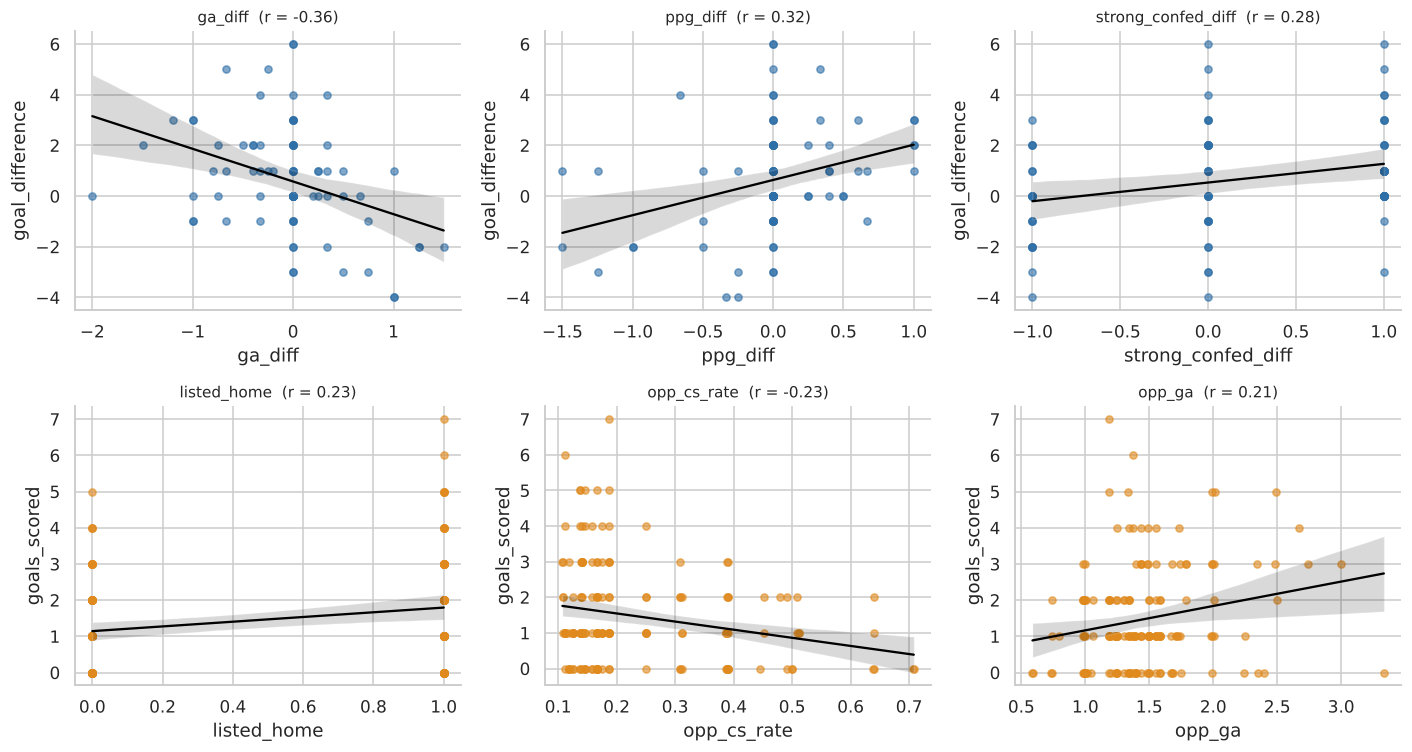

In [10]:
# Correlation heatmaps (training matches only) for the two chosen sets
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for ax, train, feats, target, title in [(axes[0], tr21, FEATURES_21, "goal_difference", "Model 2.1: goal difference"),
                                        (axes[1], tr22, FEATURES_22, "goals_scored", "Model 2.2: goals scored")]:
    sns.heatmap(train[feats + [target]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                cbar=False, ax=ax, annot_kws={"size": 7})
    ax.set_title(title); ax.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig("figures/fig2_correlation_heatmaps.png", dpi=200); plt.show()

# Scatter plots: the three variables most related to each target
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for row, (train, feats, target, col) in enumerate([(tr21, FEATURES_21, "goal_difference", BLUE), (tr22, FEATURES_22, "goals_scored", ORANGE)]):
    top3 = train[feats].corrwith(train[target]).abs().sort_values(ascending=False).index[:3]
    for ax, f in zip(axes[row], top3):
        sns.regplot(data=train, x=f, y=target, ax=ax, color=col, scatter_kws={"alpha": .6, "s": 22}, line_kws={"color": "black", "lw": 1.5})
        r = train[f].corr(train[target]); ax.set_title(f"{f}  (r = {r:.2f})", fontsize=10)
plt.tight_layout(); plt.savefig("figures/fig3_top_scatter.png", dpi=200); plt.show()

**What the EDA told us (training matches only)**

- In model 2.1, the variables most related to goal difference are **goals conceded form** (r = -0.36), **points per game** (0.32), **strong confederation** (0.28) and **host nation** (0.27). Having a host nation play helps: hosts won by +1.0 goals on average when listed first.
- *Previous match went to extra time* turned out to be constant in the training matches (extra time only appears in the knockout rounds, which are mostly in the test period), so the code removes it automatically. The remaining 8 variables are kept. The weakest one, *knockout*, is almost unrelated (r = 0.07) but stays because we need exactly 8.
- In model 2.2, **listed first** (0.23), **opponent clean-sheet rate** (-0.23) and **opponent goals conceded** (0.21) matter most. This makes football sense: you score more against leaky defences, and less against teams that often keep clean sheets.
- No variable has a VIF above 3.4, so multicollinearity is not a problem.
- Exactly **3** variable families are shared between the two models (goals for, goals against, host). The limit is 4.

**Honest note:** no variable is strongly related to the targets (all |r| < 0.4). This warns us not to expect a highly accurate model.

## 7. Linear Regression 2.1 — predicting goal difference (104 rows, 8 variables)

**What we do:** fit ordinary multiple linear regression on the 83 training matches, then judge it on the 21 later matches. Three ways of judging:

1. **Time-series cross-validation** on the training matches (expanding window, so the model is always tested on matches that come later than the ones it trained on),
2. **hold-out test** on the last 21 matches, and
3. **rolling backtest**: re-fit the model eight times and test it each time on the next 7 matches, from match 49 to 104. This uses 56 test matches instead of 21, so it is less sensitive to luck.

We report MAE (average miss, in goals), RMSE (penalises big misses) and R². The baseline is "always predict the training average".

In [11]:
# ---------- Helper functions used for both linear regressions ----------
def metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5, "R2": r2_score(y, p)}

def expanding_splits(data, n_splits=5, first_train=40):
    # Expanding-window splits that never cut a match in half (both team-rows of a match stay together)
    ids = np.sort(data.match_id.unique())
    ids = ids[ids <= ids.max()]
    edges = np.linspace(first_train, ids.max(), n_splits + 1).astype(int)
    for a, b in zip(edges[:-1], edges[1:]):
        yield np.where(data.match_id <= a)[0], np.where((data.match_id > a) & (data.match_id <= b))[0]

def cv_rmse(model, data, feats, target, **kw):
    scores = []
    for tr_i, va_i in expanding_splits(data, **kw):
        m = model.fit(data.iloc[tr_i][feats], data.iloc[tr_i][target])
        scores.append(mean_squared_error(data.iloc[va_i][target], m.predict(data.iloc[va_i][feats])) ** 0.5)
    return np.mean(scores), np.std(scores)

def rolling_backtest(make_model, full, feats, target, start=48, step=7):
    # Re-fit on all matches up to `start`, predict the next `step` matches, then move forward
    preds = pd.Series(np.nan, index=full.index)
    for s in range(start, full.match_id.max(), step):
        tr_m = full[full.match_id <= s]; te_m = full[(full.match_id > s) & (full.match_id <= s + step)]
        mdl = make_model().fit(tr_m[feats], tr_m[target]); preds.loc[te_m.index] = mdl.predict(te_m[feats])
    mask = preds.notna()
    return metrics(full.loc[mask, target], preds[mask]), preds[mask]

def lin(): return make_pipeline(StandardScaler(), LinearRegression())

In [12]:
# ---------- Fit Linear Regression 2.1 ----------
T21 = "goal_difference"
lr21 = lin().fit(tr21[FEATURES_21], tr21[T21])
p_tr, p_te = lr21.predict(tr21[FEATURES_21]), lr21.predict(te21[FEATURES_21])
base21 = DummyRegressor().fit(tr21[FEATURES_21], tr21[T21]); pb_te = base21.predict(te21[FEATURES_21])

cv_m, cv_s = cv_rmse(lin(), tr21, FEATURES_21, T21)
cv_b, _ = cv_rmse(DummyRegressor(), tr21, FEATURES_21, T21)
bt21, bt21_pred = rolling_backtest(lin, m21, FEATURES_21, T21)
bt21_base, _ = rolling_backtest(lambda: DummyRegressor(), m21, FEATURES_21, T21)

res21 = pd.DataFrame({
  "Mean baseline": {**{f"Test {k}": v for k, v in metrics(te21[T21], pb_te).items()}, "CV RMSE": cv_b, **{f"Backtest {k}": v for k, v in bt21_base.items()}},
  "Linear Regression 2.1": {**{f"Test {k}": v for k, v in metrics(te21[T21], p_te).items()}, "CV RMSE": cv_m, **{f"Backtest {k}": v for k, v in bt21.items()}},
}).T
print("Train R2:", round(r2_score(tr21[T21], p_tr), 3), "| CV RMSE: %.2f +/- %.2f" % (cv_m, cv_s))
display(res21.round(3))

# Did we get the winner right? (only matches that were not draws)
nd = te21[T21] != 0
acc = (np.sign(p_te[nd]) == np.sign(te21.loc[nd, T21])).mean()
print(f"Direction accuracy on {nd.sum()} non-drawn test matches: {acc:.0%}")

Train R2: 0.353 | CV RMSE: 1.80 +/- 0.67


,Test MAE,Test RMSE,Test R2,CV RMSE,Backtest MAE,Backtest RMSE,Backtest R2
Mean baseline,1.426,1.747,-0.302,2.038,1.526,1.956,-0.171
Linear Regression 2.1,1.520,1.951,-0.624,1.800,1.474,1.888,-0.091


Direction accuracy on 19 non-drawn test matches: 42%


In [13]:
# ---------- Inference with statsmodels: which coefficients matter? ----------
Xs = sm.add_constant(tr21[FEATURES_21]); ols21 = sm.OLS(tr21[T21], Xs).fit()
coef21 = pd.DataFrame({"coef": ols21.params, "ci_low": ols21.conf_int()[0], "ci_high": ols21.conf_int()[1], "p_value": ols21.pvalues}).round(3)
display(coef21)
print("R2 = %.3f | adjusted R2 = %.3f | F-test p-value = %.4f" % (ols21.rsquared, ols21.rsquared_adj, ols21.f_pvalue))

# ---------- Residual checks ----------
resid = tr21[T21] - ols21.fittedvalues
bp_p = het_breuschpagan(resid, Xs)[1]
print("Residual normality (Shapiro-Wilk) p = %.3f | equal-variance (Breusch-Pagan) p = %.3f" % (stats.shapiro(resid)[1], bp_p))

,coef,ci_low,ci_high,p_value
const,0.371,-0.072,0.814,0.099
gf_diff,-0.262,-1.212,0.689,0.585
ga_diff,-0.612,-1.575,0.352,0.210
host_diff,1.999,0.789,3.210,0.002
ppg_diff,0.687,-0.799,2.172,0.360
draw_rate_diff,3.158,0.431,5.884,0.024
rest_days_diff,0.123,-0.978,1.224,0.825
strong_confed_diff,0.924,0.366,1.482,0.001
knockout,-0.012,-1.263,1.239,0.985


R2 = 0.353 | adjusted R2 = 0.283 | F-test p-value = 0.0001
Residual normality (Shapiro-Wilk) p = 0.031 | equal-variance (Breusch-Pagan) p = 0.930


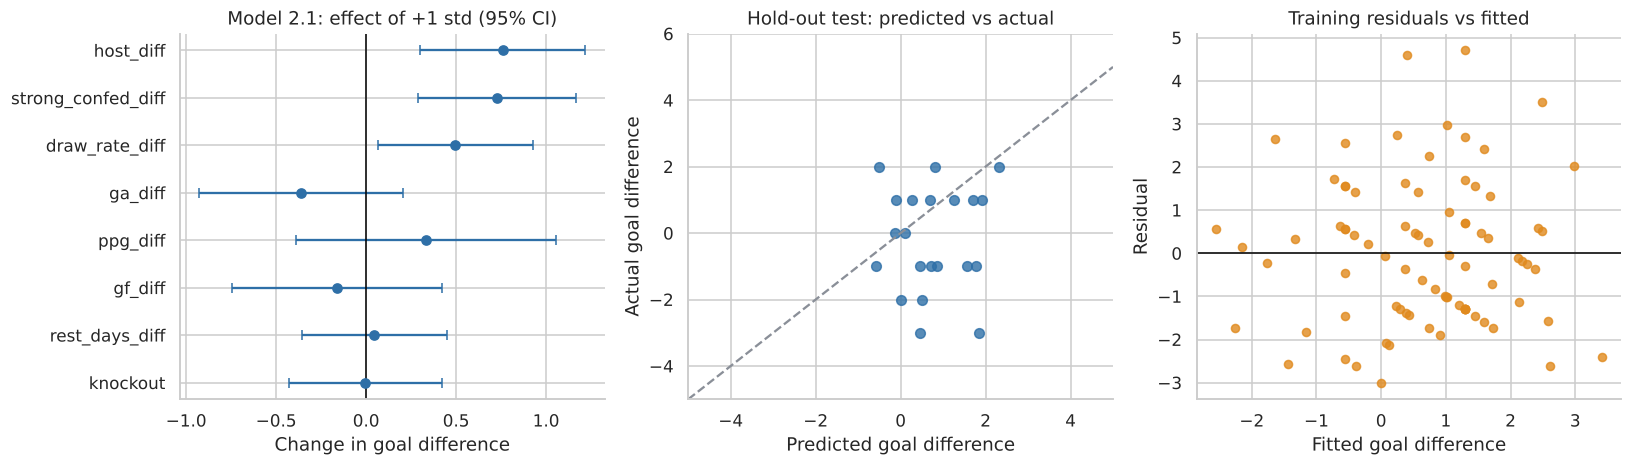

In [14]:
# ---------- Charts for model 2.1 ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

# (a) Coefficients with 95% intervals (standardised so sizes can be compared)
Z = tr21[FEATURES_21].copy(); Z = (Z - Z.mean()) / Z.std()
zfit = sm.OLS(tr21[T21], sm.add_constant(Z)).fit(); ci = zfit.conf_int().drop("const"); pr = zfit.params.drop("const")
order_ = pr.abs().sort_values().index
axes[0].errorbar(pr[order_], range(len(order_)), xerr=[pr[order_] - ci.loc[order_, 0], ci.loc[order_, 1] - pr[order_]], fmt="o", color=BLUE, capsize=3)
axes[0].axvline(0, color="black", lw=1); axes[0].set_yticks(range(len(order_))); axes[0].set_yticklabels(order_)
axes[0].set(title="Model 2.1: effect of +1 std (95% CI)", xlabel="Change in goal difference")

# (b) Predicted vs actual on the hold-out matches
axes[1].scatter(p_te, te21[T21], color=BLUE, s=40, alpha=.8)
lim = [-5, 5]; axes[1].plot(lim, lim, "--", color=GREY); axes[1].set(xlim=lim, ylim=(-5, 6), title="Hold-out test: predicted vs actual", xlabel="Predicted goal difference", ylabel="Actual goal difference")

# (c) Residuals vs fitted
axes[2].scatter(ols21.fittedvalues, resid, color=ORANGE, s=28, alpha=.8); axes[2].axhline(0, color="black", lw=1)
axes[2].set(title="Training residuals vs fitted", xlabel="Fitted goal difference", ylabel="Residual")
plt.tight_layout(); plt.savefig("figures/fig4_model21.png", dpi=200); plt.show()

**What the results show**

- **In the training data** the model explains 35% of the variation in goal difference (adjusted R² 0.28), and the overall F-test is significant (p = 0.0001). Three variables are individually significant: **host nation** (+2.0 goals for a host vs a non-host), **strong confederation** (+0.9 goals for a UEFA/CONMEBOL team vs others) and **draw-rate difference** (p = 0.024, but the sign is hard to explain, so we treat it with caution).
- **On new matches** the picture is different. On the 21 hold-out matches the linear model is *worse* than always predicting the average (RMSE 1.95 vs 1.75), and it picked the winner in only 42% of the non-drawn matches. In the rolling backtest over 56 matches it is slightly better than the baseline (RMSE 1.89 vs 1.96), but the bootstrap interval for this gain (-0.27 to +0.43 goals) includes zero.
- **Why:** with 83 training matches and 8 variables, the model fits noise. The hold-out set is also unusual: it is all knockout football, where the pre-tournament form of teams matters less and matches are tighter.
- **Residual checks:** the spread of the residuals looks even (Breusch-Pagan p = 0.93), but there are some large misses and the residuals are not perfectly normal (p = 0.03). The biggest misses are lopsided results like 7-1.

**Plain-language conclusion:** *who the host is* and *which confederation a team comes from* explain real differences in goal difference, but our 8 variables do not let us predict individual matches better than a simple average.

## 8. Linear Regression 2.2 — predicting goals scored by a team (208 rows, 8 variables)

The same steps as for model 2.1, using the 8 variables chosen in section 6. Goals are small whole numbers (0, 1, 2…), so we also keep an eye on whether the linear model predicts impossible negative goals.

In [15]:
T22 = "goals_scored"
lr22 = lin().fit(tr22[FEATURES_22], tr22[T22])
q_tr, q_te = lr22.predict(tr22[FEATURES_22]), lr22.predict(te22[FEATURES_22])
base22 = DummyRegressor().fit(tr22[FEATURES_22], tr22[T22]); qb_te = base22.predict(te22[FEATURES_22])
cv_m2, cv_s2 = cv_rmse(lin(), tr22, FEATURES_22, T22); cv_b2, _ = cv_rmse(DummyRegressor(), tr22, FEATURES_22, T22)
bt22, bt22_pred = rolling_backtest(lin, m22, FEATURES_22, T22)
bt22_base, _ = rolling_backtest(lambda: DummyRegressor(), m22, FEATURES_22, T22)

res22 = pd.DataFrame({
  "Mean baseline": {**{f"Test {k}": v for k, v in metrics(te22[T22], qb_te).items()}, "CV RMSE": cv_b2, **{f"Backtest {k}": v for k, v in bt22_base.items()}},
  "Linear Regression 2.2": {**{f"Test {k}": v for k, v in metrics(te22[T22], q_te).items()}, "CV RMSE": cv_m2, **{f"Backtest {k}": v for k, v in bt22.items()}},
}).T
print("Train R2:", round(r2_score(tr22[T22], q_tr), 3), "| CV RMSE: %.2f +/- %.2f" % (cv_m2, cv_s2))
display(res22.round(3))
print("Negative goal predictions on test rows:", int((q_te < 0).sum()), "of", len(q_te))

Xs2 = sm.add_constant(tr22[FEATURES_22]); ols22 = sm.OLS(tr22[T22], Xs2).fit()
display(pd.DataFrame({"coef": ols22.params, "ci_low": ols22.conf_int()[0], "ci_high": ols22.conf_int()[1], "p_value": ols22.pvalues}).round(3))
print("R2 = %.3f | adjusted R2 = %.3f | F-test p-value = %.4f" % (ols22.rsquared, ols22.rsquared_adj, ols22.f_pvalue))
resid2 = tr22[T22] - ols22.fittedvalues
print("Residual normality (Shapiro-Wilk) p = %.4f | equal-variance (Breusch-Pagan) p = %.3f" % (stats.shapiro(resid2)[1], het_breuschpagan(resid2, Xs2)[1]))

Train R2: 0.169 | CV RMSE: 1.24 +/- 0.25


,Test MAE,Test RMSE,Test R2,CV RMSE,Backtest MAE,Backtest RMSE,Backtest R2
Mean baseline,1.045,1.315,-0.002,1.307,1.061,1.290,-0.003
Linear Regression 2.2,1.084,1.508,-0.318,1.244,1.021,1.341,-0.084


Negative goal predictions on test rows: 1 of 42


,coef,ci_low,ci_high,p_value
const,2.514,0.821,4.207,0.004
team_ga,-0.574,-1.058,-0.089,0.021
is_host,0.466,-0.372,1.304,0.274
team_fts_rate,-0.523,-2.160,1.114,0.529
opp_gf,-0.268,-0.934,0.397,0.427
opp_ga,0.320,-0.296,0.937,0.306
opp_cs_rate,-1.574,-3.565,0.417,0.120
opp_win_rate,-0.309,-2.698,2.080,0.799
listed_home,0.582,0.172,0.992,0.006


R2 = 0.169 | adjusted R2 = 0.126 | F-test p-value = 0.0003
Residual normality (Shapiro-Wilk) p = 0.0000 | equal-variance (Breusch-Pagan) p = 0.150


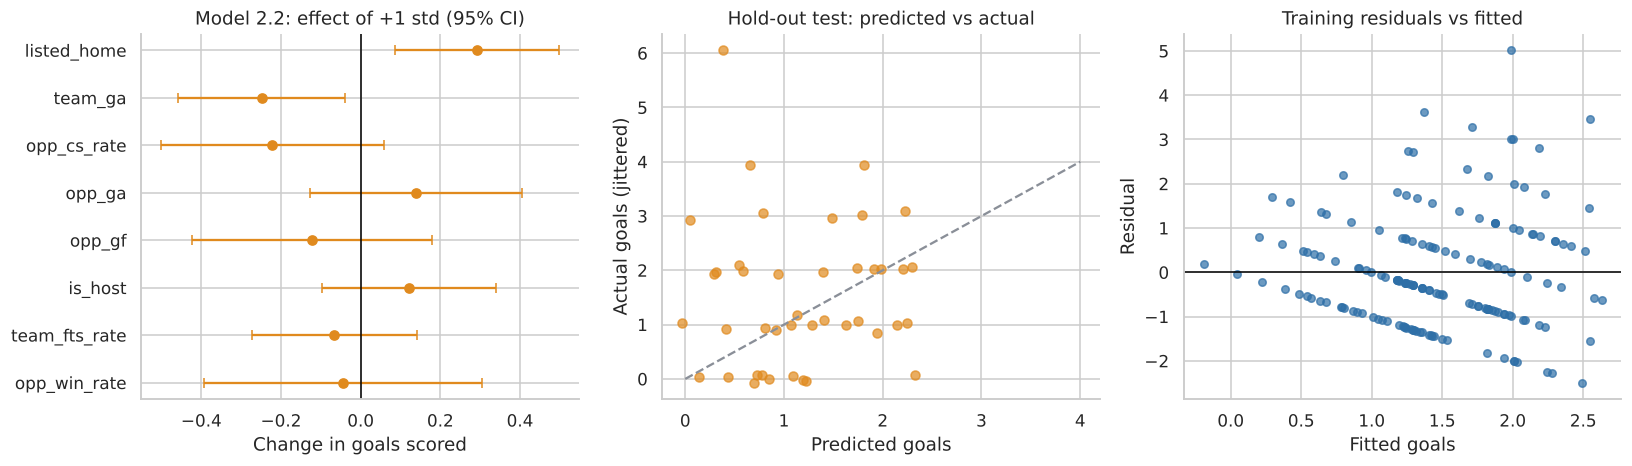

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
Z2 = tr22[FEATURES_22].copy(); Z2 = (Z2 - Z2.mean()) / Z2.std()
zf2 = sm.OLS(tr22[T22], sm.add_constant(Z2)).fit(); ci2 = zf2.conf_int().drop("const"); pr2 = zf2.params.drop("const")
o2 = pr2.abs().sort_values().index
axes[0].errorbar(pr2[o2], range(len(o2)), xerr=[pr2[o2] - ci2.loc[o2, 0], ci2.loc[o2, 1] - pr2[o2]], fmt="o", color=ORANGE, capsize=3)
axes[0].axvline(0, color="black", lw=1); axes[0].set_yticks(range(len(o2))); axes[0].set_yticklabels(o2)
axes[0].set(title="Model 2.2: effect of +1 std (95% CI)", xlabel="Change in goals scored")

jit = np.random.default_rng(SEED).normal(0, .08, len(te22))
axes[1].scatter(q_te, te22[T22] + jit, color=ORANGE, s=35, alpha=.7)
axes[1].plot([0, 4], [0, 4], "--", color=GREY); axes[1].set(title="Hold-out test: predicted vs actual", xlabel="Predicted goals", ylabel="Actual goals (jittered)")
axes[2].scatter(ols22.fittedvalues, resid2, color=BLUE, s=24, alpha=.7); axes[2].axhline(0, color="black", lw=1)
axes[2].set(title="Training residuals vs fitted", xlabel="Fitted goals", ylabel="Residual")
plt.tight_layout(); plt.savefig("figures/fig5_model22.png", dpi=200); plt.show()

**What the results show**

- **In the training data** the model explains 17% of the variation in goals scored (adjusted R² 0.13, F-test p = 0.0003). Two variables are individually significant: **listed first** (+0.58 goals) and **the team's own goals-conceded form** (-0.57 per goal conceded).
- **On new matches** the linear model is again no better than the average: hold-out RMSE 1.51 vs 1.32 for the baseline; backtest RMSE 1.34 vs 1.29. This is partly because goals are noisy: even the best possible model cannot predict whether a team scores 1 or 3 goals.
- **Count data issue:** one hold-out prediction was negative, which is impossible for goals. The Poisson model in the next section avoids this.
- **Residuals are not normal** (Shapiro-Wilk p < 0.001), as expected for count data. This is a known weakness of using a straight-line model for goals.

## 9. Trying to improve the linear models

We try a short list of sensible improvements, one at a time, and measure each with the same time-aware cross-validation and rolling backtest. Test matches are never used to choose between them.

1. **Regularisation** (Ridge, Lasso, ElasticNet): shrinks noisy coefficients, which helps when there are 8 variables and few matches.
2. **Feature engineering:** (a) add a *strength × opponent weakness* interaction, (b) use a stronger shrinkage constant for the form variables (K = 4), (c) a smaller model with only the 4 strongest variables.
3. **Target transformation** (model 2.2 only): predict with a Poisson model, which is built for counts and can never predict negative goals.

In [17]:
# --- Experiment runner: every option is judged by CV on training matches and by the rolling backtest ---
def run_experiment(name, make_model, train, full, feats, target, rows):
    cv_mean, cv_sd = cv_rmse(make_model(), train, feats, target)
    bt, _ = rolling_backtest(make_model, full, feats, target)
    rows.append({"Experiment": name, "CV RMSE": cv_mean, "Backtest RMSE": bt["RMSE"], "Backtest MAE": bt["MAE"], "Backtest R2": bt["R2"]})

def ridge(): return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
def lasso(): return make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=SEED, max_iter=20000))
def enet():  return make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.2,.5,.8], cv=5, random_state=SEED, max_iter=20000))

# Helper: add an interaction between the two strongest variables (chosen from TRAINING data only)
def with_interaction(data, feats, train):
    top2 = train[feats].corrwith(train[data.columns[data.columns.isin([TARGET_NAME])][0]]).abs().sort_values(ascending=False).index[:2]
    new = f"{top2[0]}_x_{top2[1]}"; d = data.copy(); d[new] = d[top2[0]] * d[top2[1]]
    return d, feats + [new], new

exp_rows = {"2.1": [], "2.2": []}
for tag, train, full, feats, target in [("2.1", tr21, m21, FEATURES_21, T21), ("2.2", tr22, m22, FEATURES_22, T22)]:
    rows = exp_rows[tag]
    run_experiment("Plain linear regression", lin, train, full, feats, target, rows)
    run_experiment("Ridge", ridge, train, full, feats, target, rows)
    run_experiment("Lasso", lasso, train, full, feats, target, rows)
    run_experiment("ElasticNet", enet, train, full, feats, target, rows)
    # Smaller model: 4 strongest variables (picked from training matches only)
    top4 = train[feats].corrwith(train[target]).abs().sort_values(ascending=False).index[:4].tolist()
    run_experiment("Linear, 4 strongest variables", lin, train, full, top4, target, rows)
    # Interaction between the two strongest variables
    TARGET_NAME = target
    full_i, feats_i, newname = with_interaction(full, feats, train)
    train_i = full_i[full_i.match_id.isin(train_ids)]
    run_experiment(f"Linear + interaction ({newname})", lin, train_i, full_i, feats_i, target, rows)
    run_experiment("Ridge + interaction", ridge, train_i, full_i, feats_i, target, rows)

exp21, exp22 = [pd.DataFrame(exp_rows[k]).set_index("Experiment") for k in ["2.1", "2.2"]]
print("Model 2.1 experiments"); display(exp21.round(3))
print("Model 2.2 experiments"); display(exp22.round(3))

Model 2.1 experiments


,CV RMSE,Backtest RMSE,Backtest MAE,Backtest R2
Experiment,,,,
Plain linear regression,1.800,1.888,1.474,-0.091
Ridge,1.758,1.784,1.370,0.026
Lasso,2.038,1.880,1.448,-0.082
ElasticNet,1.881,1.843,1.406,-0.039
"Linear, 4 strongest variables",1.660,1.731,1.264,0.083
Linear + interaction (ga_diff_x_ppg_diff),2.141,2.072,1.596,-0.314
Ridge + interaction,1.992,1.954,1.480,-0.169


Model 2.2 experiments


,CV RMSE,Backtest RMSE,Backtest MAE,Backtest R2
Experiment,,,,
Plain linear regression,1.244,1.341,1.021,-0.084
Ridge,1.198,1.268,0.975,0.031
Lasso,1.242,1.310,0.998,-0.033
ElasticNet,1.219,1.290,0.990,-0.002
"Linear, 4 strongest variables",1.283,1.353,1.023,-0.103
Linear + interaction (listed_home_x_opp_cs_rate),1.261,1.329,1.007,-0.063
Ridge + interaction,1.216,1.279,0.982,0.014


In [18]:
# Experiment: stronger shrinkage (K = 4) for the form variables. We rebuild only the form columns and rerun the backtest.
def rebuild_with_K(K_new):
    global K
    old = K; K = K_new
    t = tg.copy()
    for s in ["gf","ga","pts","win","draw","cs","fts"]:
        g = t.groupby("team")[s]
        prev_sum = g.cumsum() - t[s]; n_prev = t.groupby("team").cumcount()
        t[f"{s}_form"] = (prev_sum + K_new * league_prior_by_date(s)) / (n_prev + K_new)
    K = old
    lk = t.set_index(["match_id","team"])[feat_cols]
    Hk = lk.loc[list(zip(df.match_id, df.home_team))].reset_index(drop=True); Ak = lk.loc[list(zip(df.match_id, df.away_team))].reset_index(drop=True)
    d21 = m21.copy(); d21["gf_diff"] = Hk.gf_form - Ak.gf_form; d21["ga_diff"] = Hk.ga_form - Ak.ga_form
    d21["ppg_diff"] = Hk.pts_form - Ak.pts_form; d21["draw_rate_diff"] = Hk.draw_form - Ak.draw_form
    Tk = lk.loc[list(zip(t.match_id, t.team))].reset_index(drop=True); Ok = lk.loc[list(zip(t.match_id, t.opp))].reset_index(drop=True)
    d22 = m22.copy(); d22["team_gf"] = Tk.gf_form; d22["team_ga"] = Tk.ga_form; d22["team_fts_rate"] = Tk.fts_form
    d22["opp_gf"] = Ok.gf_form; d22["opp_ga"] = Ok.ga_form; d22["opp_cs_rate"] = Ok.cs_form; d22["opp_win_rate"] = Ok.win_form
    return d21, d22

kres = []
for K_try in [1, 2, 4, 8]:
    d21k, d22k = rebuild_with_K(K_try)
    b1, _ = rolling_backtest(lin, d21k, FEATURES_21, T21); b2, _ = rolling_backtest(lin, d22k, FEATURES_22, T22)
    kres.append({"K": K_try, "2.1 Backtest RMSE": b1["RMSE"], "2.2 Backtest RMSE": b2["RMSE"]})
kres = pd.DataFrame(kres).set_index("K"); display(kres.round(3))

,2.1 Backtest RMSE,2.2 Backtest RMSE
K,,
1,1.865,1.321
2,1.888,1.341
4,1.913,1.364
8,1.935,1.375


In [19]:
# Poisson regression for model 2.2 (goals are counts; predictions are always >= 0)
def poisson(): return make_pipeline(StandardScaler(), PoissonRegressor(alpha=1.0, max_iter=1000))
run_experiment("Poisson regression (alpha=1)", poisson, tr22, m22, FEATURES_22, T22, exp_rows["2.2"])
exp22 = pd.DataFrame(exp_rows["2.2"]).set_index("Experiment"); display(exp22.round(3))
pois = poisson().fit(tr22[FEATURES_22], tr22[T22]); pp_te = pois.predict(te22[FEATURES_22])
print("Poisson hold-out test:", {k: round(v, 3) for k, v in metrics(te22[T22], pp_te).items()}, "| min prediction:", round(pp_te.min(), 2))

,CV RMSE,Backtest RMSE,Backtest MAE,Backtest R2
Experiment,,,,
Plain linear regression,1.244,1.341,1.021,-0.084
Ridge,1.198,1.268,0.975,0.031
Lasso,1.242,1.310,0.998,-0.033
ElasticNet,1.219,1.290,0.990,-0.002
"Linear, 4 strongest variables",1.283,1.353,1.023,-0.103
Linear + interaction (listed_home_x_opp_cs_rate),1.261,1.329,1.007,-0.063
Ridge + interaction,1.216,1.279,0.982,0.014
Poisson regression (alpha=1),1.185,1.250,0.961,0.059


Poisson hold-out test: {'MAE': 1.01, 'RMSE': 1.389, 'R2': -0.117} | min prediction: 0.65


**What we learned from the improvement experiments** (judged by cross-validation and the 56-match backtest, not by the hold-out test)

- **Regularisation helps most.** Ridge regression lowers backtest RMSE from 1.89 to 1.78 in model 2.1 and from 1.34 to 1.27 in model 2.2. It also turns backtest R² slightly positive in both. Lasso and ElasticNet help less, because they remove variables when most carry only a little information.
- **A smaller model helps model 2.1** (4 strongest variables: backtest RMSE 1.73, the best linear result), which confirms that with 83 training matches fewer variables is safer. In model 2.2 the smaller model does not help.
- **Interactions do not help.** Multiplying the two strongest variables makes both models worse, another sign of overfitting.
- **Shrinkage constant K:** the choice of K changes the backtest RMSE only slightly (differences of about 0.05), so our results do not depend on this choice. K = 2 is kept, because choosing K = 1 on this evidence alone would be picking noise.
- **Poisson regression** (model 2.2) is the best model of all tried for goals: backtest RMSE 1.25 and MAE 0.96. It is built for counts and never predicts negative goals.

## 10. Competing models and recommendation

Linear regression is one of many regression models. Here we test two tree-based ensembles, **Random Forest** and **Gradient Boosting**. They can learn curved and interacting relationships that a straight-line model cannot. We use the same 8 variables, the same splits and the same metrics. Their settings are chosen only by cross-validation inside the training matches (small grids, because there are few matches).

In [20]:
tscv = lambda data: list(expanding_splits(data))

def tuned_rf(train, feats, target):
    grid = {"max_depth": [2, 3, 5], "min_samples_leaf": [3, 6, 10]}
    gs = GridSearchCV(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), grid,
                      cv=tscv(train), scoring="neg_root_mean_squared_error").fit(train[feats], train[target])
    return gs.best_params_
def tuned_gb(train, feats, target):
    grid = {"max_depth": [2, 3], "learning_rate": [0.03, 0.1], "max_iter": [50, 150], "min_samples_leaf": [8, 15]}
    gs = GridSearchCV(HistGradientBoostingRegressor(random_state=SEED, l2_regularization=1.0), grid,
                      cv=tscv(train), scoring="neg_root_mean_squared_error").fit(train[feats], train[target])
    return gs.best_params_

best_params = {}
for tag, train, feats, target in [("2.1", tr21, FEATURES_21, T21), ("2.2", tr22, FEATURES_22, T22)]:
    best_params[tag] = {"RF": tuned_rf(train, feats, target), "GB": tuned_gb(train, feats, target)}
    print(tag, best_params[tag])

2.1 {'RF': {'max_depth': 3, 'min_samples_leaf': 3}, 'GB': {'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 50, 'min_samples_leaf': 8}}


2.2 {'RF': {'max_depth': 2, 'min_samples_leaf': 3}, 'GB': {'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 150, 'min_samples_leaf': 15}}


In [21]:
def build_models(tag):
    bp = best_params[tag]
    ms = {"Mean baseline": lambda: DummyRegressor(),
          "Linear Regression": lin, "Ridge": ridge, "Lasso": lasso,
          "Random Forest": lambda: RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **bp["RF"]),
          "Gradient Boosting": lambda: HistGradientBoostingRegressor(random_state=SEED, l2_regularization=1.0, **bp["GB"])}
    if tag == "2.2": ms["Poisson"] = poisson
    return ms

final = {}
fitted_test_preds = {}
for tag, train, test, full, feats, target in [("2.1", tr21, te21, m21, FEATURES_21, T21), ("2.2", tr22, te22, m22, FEATURES_22, T22)]:
    rows = []
    for name, mk in build_models(tag).items():
        mdl = mk().fit(train[feats], train[target]); pt = mdl.predict(test[feats]); fitted_test_preds[(tag, name)] = pt
        cv_mean, _ = cv_rmse(mk(), train, feats, target)
        bt, _ = rolling_backtest(mk, full, feats, target)
        t = metrics(test[target], pt)
        rows.append({"Model": name, "CV RMSE": cv_mean, "Test MAE": t["MAE"], "Test RMSE": t["RMSE"], "Test R2": t["R2"],
                     "Backtest MAE": bt["MAE"], "Backtest RMSE": bt["RMSE"], "Backtest R2": bt["R2"]})
    final[tag] = pd.DataFrame(rows).set_index("Model")
    print(f"\nModel {tag}: all models, same variables and splits"); display(final[tag].round(3))
final["2.1"].to_csv("data/comparison_model21.csv"); final["2.2"].to_csv("data/comparison_model22.csv")


Model 2.1: all models, same variables and splits


,CV RMSE,Test MAE,Test RMSE,Test R2,Backtest MAE,Backtest RMSE,Backtest R2
Model,,,,,,,
Mean baseline,2.038,1.426,1.747,-0.302,1.526,1.956,-0.171
Linear Regression,1.800,1.520,1.951,-0.624,1.474,1.888,-0.091
Ridge,1.758,1.477,1.893,-0.528,1.370,1.784,0.026
Lasso,2.038,1.436,1.877,-0.502,1.448,1.880,-0.082
Random Forest,1.750,1.411,1.934,-0.595,1.304,1.756,0.057
Gradient Boosting,1.864,1.420,1.839,-0.443,1.461,1.908,-0.114



Model 2.2: all models, same variables and splits


,CV RMSE,Test MAE,Test RMSE,Test R2,Backtest MAE,Backtest RMSE,Backtest R2
Model,,,,,,,
Mean baseline,1.307,1.045,1.315,-0.002,1.061,1.290,-0.003
Linear Regression,1.244,1.084,1.508,-0.318,1.021,1.341,-0.084
Ridge,1.198,1.036,1.430,-0.185,0.975,1.268,0.031
Lasso,1.242,1.082,1.505,-0.312,0.998,1.310,-0.033
Random Forest,1.299,1.054,1.383,-0.109,1.024,1.299,-0.017
Gradient Boosting,1.300,1.132,1.516,-0.332,1.031,1.339,-0.079
Poisson,1.185,1.010,1.389,-0.117,0.961,1.250,0.059


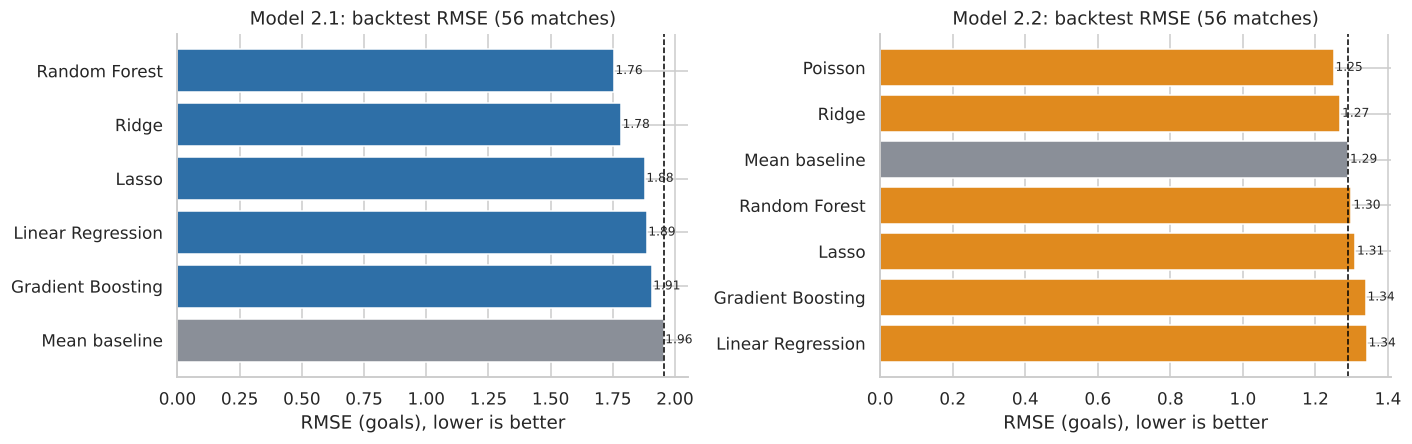

In [22]:
# Comparison chart: backtest RMSE (lower is better). The baseline is the line to beat.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, tag, col in [(axes[0], "2.1", BLUE), (axes[1], "2.2", ORANGE)]:
    d = final[tag]["Backtest RMSE"].sort_values()
    colors = [GREY if n == "Mean baseline" else col for n in d.index]
    ax.barh(d.index, d.values, color=colors); ax.invert_yaxis()
    ax.axvline(final[tag].loc["Mean baseline", "Backtest RMSE"], color="black", ls="--", lw=1)
    for y, v in enumerate(d.values): ax.text(v + .005, y, f"{v:.2f}", va="center", fontsize=8)
    ax.set(title=f"Model {tag}: backtest RMSE (56 matches)", xlabel="RMSE (goals), lower is better")
plt.tight_layout(); plt.savefig("figures/fig6_model_comparison.png", dpi=200); plt.show()

In [23]:
# How sure are we? Bootstrap over MATCHES (not rows) so both team-rows of a match stay together.
def bootstrap_gain(full, feats, target, make_a, make_b, n=500):
    _, pa = rolling_backtest(make_a, full, feats, target); _, pb = rolling_backtest(make_b, full, feats, target)
    d = full.loc[pa.index, [ "match_id", target]].copy(); d["ea"] = (d[target] - pa) ** 2; d["eb"] = (d[target] - pb) ** 2
    per_match = d.groupby("match_id")[["ea", "eb"]].mean(); rng = np.random.default_rng(SEED); out = []
    for _ in range(n):
        s = per_match.sample(len(per_match), replace=True, random_state=int(rng.integers(1e9)))
        out.append(np.sqrt(s.eb.mean()) - np.sqrt(s.ea.mean()))   # positive = A better (lower RMSE) than B
    return np.percentile(out, [2.5, 50, 97.5])

for tag, full, feats, target in [("2.1", m21, FEATURES_21, T21), ("2.2", m22, FEATURES_22, T22)]:
    lo, mid, hi = bootstrap_gain(full, feats, target, lin, lambda: DummyRegressor())
    print(f"Model {tag}: linear regression RMSE advantage over the mean baseline = {mid:+.3f} goals (95% CI {lo:+.3f} to {hi:+.3f})")

Model 2.1: linear regression RMSE advantage over the mean baseline = +0.071 goals (95% CI -0.266 to +0.431)


Model 2.2: linear regression RMSE advantage over the mean baseline = -0.048 goals (95% CI -0.161 to +0.066)


**What the comparison shows**

| | Model 2.1 (goal difference) | Model 2.2 (goals scored) |
|---|---|---|
| Best by backtest | Random Forest (RMSE 1.76) | Poisson (RMSE 1.25) |
| Best linear model | Ridge (1.78) | Ridge (1.27) |
| Plain linear regression | 1.89 | 1.34 |
| Mean baseline | 1.96 | 1.29 |

- Every model beats the baseline only slightly, and gradient boosting is no better than plain linear regression. Models that are more flexible (Random Forest, Gradient Boosting) do **not** clearly beat well-regularised linear models. This is typical for 104 matches.
- The bootstrap intervals for the plain linear model's advantage over the baseline include zero in both tasks, so we cannot claim the plain linear models are better than simply predicting the average.

**Recommendation**

1. For **goal difference (2.1)** use **Ridge regression**: it is nearly as accurate as Random Forest, and it keeps coefficients we can explain to a non-expert. Random Forest has the lowest backtest RMSE, but its hold-out result is not better than Ridge and it cannot be easily explained.
2. For **goals scored (2.2)** use **Poisson regression**, as it matches the type of data (counts) and was the best on every backtest measure.
3. Whichever model is chosen, **expect modest accuracy**. Pre-match information built only from the tournament itself explains a small part of what happens in a football match.

**Limitations to state in the report:** only 104 matches; 21 hold-out matches are mostly knockout games; choosing the best model by backtest involves some selection; no data on squad quality, because the only ranking available was published after the tournament.

## 11. Summary tables used in the report

In [24]:
summary = []
for tag, target, ols, tr_, te_ in [("2.1", T21, ols21, tr21, te21), ("2.2", T22, ols22, tr22, te22)]:
    f = final[tag]
    best_name = f.drop("Mean baseline")["Backtest RMSE"].idxmin()
    summary.append({"Task": tag, "Rows": 104 if tag == "2.1" else 208, "Variables": 8,
                    "Linear test RMSE": f.loc["Linear Regression", "Test RMSE"], "Baseline test RMSE": f.loc["Mean baseline", "Test RMSE"],
                    "Linear backtest RMSE": f.loc["Linear Regression", "Backtest RMSE"], "Baseline backtest RMSE": f.loc["Mean baseline", "Backtest RMSE"],
                    "Linear R2 (train)": ols.rsquared, "Adj R2 (train)": ols.rsquared_adj, "Best model by backtest": best_name})
display(pd.DataFrame(summary).round(3))
print("Final variables, model 2.1:", FEATURES_21); print("Final variables, model 2.2:", FEATURES_22)
print("Saved: data/model21_dataset.csv, data/model22_dataset.csv, data/comparison_model21.csv, data/comparison_model22.csv, figures/*.png")

,Task,Rows,Variables,Linear test RMSE,Baseline test RMSE,Linear backtest RMSE,Baseline backtest RMSE,Linear R2 (train),Adj R2 (train),Best model by backtest
0,2.1,104,8,1.951,1.747,1.888,1.956,0.353,0.283,Random Forest
1,2.2,208,8,1.508,1.315,1.341,1.290,0.169,0.126,Poisson


Final variables, model 2.1: ['gf_diff', 'ga_diff', 'host_diff', 'ppg_diff', 'draw_rate_diff', 'rest_days_diff', 'strong_confed_diff', 'knockout']
Final variables, model 2.2: ['team_ga', 'is_host', 'team_fts_rate', 'opp_gf', 'opp_ga', 'opp_cs_rate', 'opp_win_rate', 'listed_home']
Saved: data/model21_dataset.csv, data/model22_dataset.csv, data/comparison_model21.csv, data/comparison_model22.csv, figures/*.png


**End of analysis.** All datasets are in `data/` and all charts in `figures/`, so every number in the report can be traced back to this notebook.